# GANs Image Generation

In this notebook, we will explore how Generative Adversarial Networks (GANs) generate images. We will use a pretrained GAN model (BigGAN) to generate images from random noise.

## Instructions
1. Run the code below to generate an image from random noise.
2. Modify the latent vector to generate different images.
3. Experiment with generating different images by altering the latent vector and visualizing the results.


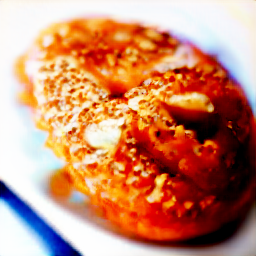

In [11]:
import torch
from pytorch_pretrained_biggan import (BigGAN, one_hot_from_int) # Had to use this because apparently torch7 is outdated

from torchvision import transforms
from PIL import Image

# Load pretrained BigGAN model
model = BigGAN.from_pretrained('biggan-deep-256')

# Generate random latent vector (noise)

# torch.manual_seed(n) so it keeps generating the same vector
latent_vector = torch.randn(1, 128)  # 128 is the size of the input vector for BigGAN
# torch.zeroes makes the latent vectors all zeroes

# According to Imagenet_classes, 932 is a bagel. Since the index starts with a 0, subract 1 from the numbered list
class_label = torch.from_numpy(one_hot_from_int(931, batch_size=1))  # shape (1, 1000)
truncation = 0.4
# Generate image
with torch.no_grad():
    generated_image = model(latent_vector, class_label, truncation)

# Convert the tensor to a displayable image
generated_image = generated_image.squeeze().permute(1,2,0).cpu().numpy()
generated_image = (generated_image * 255).clip(0,255).astype('uint8')
Image.fromarray(generated_image)



## Reflection

Now that you have generated images, write a brief report reflecting on your observations:

1. How did the generated images change when you modified the latent vector?

When I modified the latent vector, the generated images were quite different from one another. When two latent vectors are close to one another, the changes are subtle but when the vectors are far apart,there is a greater differences, and some might not even look like a bagel. For example, latent vector 99 and latent vector 79 produced images that looked extremely different.

2. What patterns did you notice in the generated images? Were they realistic?

Some were realistic and some weren't, it all depends on where the random latent vector lands in the latent space and how well trained or how well defined the features are. 

3. How does the process of generating images from noise differ from traditional image generation methods?

Traditional image generation usually has something to define the visual content but with GANs, the images are being generated from random noise vectors with no design rules involved. The generator maps the noise of images across the latent space by distributing and exemplifying its features. This makes GANs powerful and unpredictable cause you will never know which random noise vector you will get unless you control it by hardcoding.

4. What challenges or limitations did you observe with the GAN model?

It was a bit challenging to understand how the latent space worked and to get some images that looked real. The setup was a bit hard aswell because I kept running into so many errors and apparently I wasn't supposed to use the library provided in the assignment. 